# 02 · Hardware budget, architectures, and the state of the art

## The chip, block by block

```
PDM mic ─► CIC R=64 ─► 16 kHz ─► 16 IIR band-pass biquads ─► |y| sum over 16 ms ─► log2 ─► 16 × uint8 / frame
  (~0.5 tile)                     (~4 tiles: 1,270 FF + 1,660 cells, yosys)                   │
                                                                                             ▼
                        QSPI Pmod (flash = weights, PSRAM = big state) ◄──► classifier engine (MAC, sequencer)
                                                                             + on-chip state ─► wake
```

Three tiers of every block, each checked against the next:

| tier | where | status |
|---|---|---|
| fast numba model | `model/features.py` | used for training/testing (~1 ms per 1.6 s window) |
| bit-exact golden model | `model/frontend.py` | `test_bitexact.py`: fast == golden |
| Verilog | `src/pdm_cic.v`, `src/filterbank.v` | cocotb: RTL == golden |
| Pi 5 recorder | `hw/pi_mics/pdm.py` | `test_pdm.py`: == golden CIC (so recordings are chip-exact) |

Classifier: float in torch for now. Quantised golden model and RTL follow once the
architecture and size are chosen from these experiments.

## Cost model: from a network to tiles

The question is how many Tiny Tapeout tiles a given network costs. The assumptions, all in
`model/archs.py`, are:

| item | value | basis |
|---|---|---|
| storage per tile | ~320 flip-flops | sky130 tile 167×108 µm ≈ 1k standard cells at routable density; our yosys runs |
| front end | ~5 tiles | CIC + 16-band filterbank (measured: ~1,270 FF + 1,660 cells) + VAD |
| classifier engine | ~2 tiles | QSPI controller, 8×8 MAC + 24-bit accumulator, sequencer, activation LUTs (estimate) |
| weights | **off-chip**, QSPI flash, 8-bit | read once per output step |
| QSPI bandwidth | ~4.1 MB/s ≈ 65 kB per 16 ms frame | SCK = 16.384 MHz / 2, 4 data lines |
| compute | 1 MAC per clock = 262k MACs per frame | far above every model here, so never the limit |
| recurrent state (GRU, minGRU) | on-chip flip-flops | small: H values + an H-value update buffer |
| TCN history / transformer K-V cache | **PSRAM** on the same QSPI Pmod | too big for flip-flops; only a working set stays on chip; the traffic is added to the QSPI load |

So **tiles ≈ 7 + on-chip state bits / 320**. Parameters mostly cost QSPI bandwidth, not
tiles. That is why the tile column doesn't grow 4× when the parameters do.

The ladder: 5 sizes per architecture, **~4× parameters apart**, with the middle one at
~16 tiles (the 8×2 maximum).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import archs
from nbutil import ARCH_COLOR, ARCH_ORDER, TILE_BUDGET

rows = []
for a in ARCH_ORDER + ["mingru"]:
    for i, w in enumerate(archs.WIDTHS[a]):
        m = archs.build(a, w)
        rows.append({"arch": a, "size": i, "width": w, **archs.cost(m)})
cost = pd.DataFrame(rows)
with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(cost[["arch", "size", "width", "params", "tiles", "classifier_tiles", "state_on_chip_B",
                  "state_psram_B", "qspi_kB_per_frame", "qspi_load", "macs_per_frame"]])

,arch,size,width,params,tiles,classifier_tiles,state_on_chip_B,state_psram_B,qspi_kB_per_frame,qspi_load,macs_per_frame
0,gru,0,43,7913,9.6,4.6,102,0,7.9,0.12,7913
1,gru,1,86,26919,11.7,6.7,188,0,26.9,0.41,26919
2,gru,2,172,98213,16.0,11.0,360,0,98.2,1.50,98213
3,gru,3,344,373929,24.6,19.6,704,0,373.9,5.71,373929
4,gru,4,688,1457873,41.8,36.8,1392,0,1457.9,22.25,1457873
5,mingru,0,43,5290,9.6,4.6,102,0,5.3,0.08,5290
6,mingru,1,86,17975,11.7,6.7,188,0,18.0,0.27,17975
7,mingru,2,172,65533,16.0,11.0,360,0,65.5,1.00,65533
8,mingru,3,344,249401,24.6,19.6,704,0,249.4,3.81,249401
9,mingru,4,688,972145,41.8,36.8,1392,0,972.1,14.83,972145


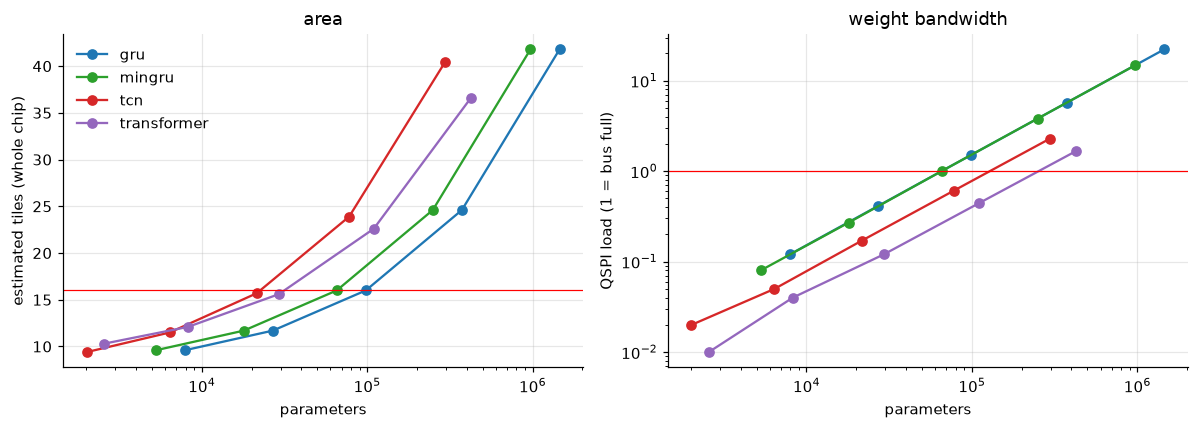

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a in ARCH_ORDER:
    d = cost[cost["arch"] == a]
    axes[0].plot(d["params"], d["tiles"], "o-", color=ARCH_COLOR[a], label=a)
    axes[1].plot(d["params"], d["qspi_load"], "o-", color=ARCH_COLOR[a], label=a)
axes[0].axhline(TILE_BUDGET, color="red", lw=0.8)
axes[0].set(xscale="log", xlabel="parameters", ylabel="estimated tiles (whole chip)", title="area")
axes[1].axhline(1, color="red", lw=0.8)
axes[1].set(xscale="log", yscale="log", xlabel="parameters", ylabel="QSPI load (1 = bus full)", title="weight bandwidth")
axes[0].legend()
plt.tight_layout()

**What the cost model says, before any training:**

* **Recurrent nets (GRU, minGRU)** keep their whole state on chip, and it is tiny. At 16
  tiles their limit is the **QSPI bus**: every weight is read every 16 ms frame. The
  16-tile GRU (98k params) needs 1.5× the bus at 8-bit weights, so it needs 4-bit weights
  or a 32 ms frame. minGRU's 65k params just fit.
* **TCN and transformer** run at a stride (2 and 4 frames per output), so they read their
  weights 2–4× less often. They are the bandwidth-efficient options, but their history and
  K-V cache have to live in PSRAM.
* **Compute is never the limit.** One MAC per clock gives 262k MACs per frame, more than
  any model here needs.

## The architectures

Two of them copy what the big players published (details and references in
[`SOA.md`](SOA.md)):

| arch | structure | streaming state | why try it |
|---|---|---|---|
| **apple** | Apple's "Hey Siri" first stage: 5 sigmoid hidden layers over the last 20 frames, every frame | 20-frame history (PSRAM) | Apple's always-on detector is ~13–31k weights (derived in SOA.md §2.1); our smallest "apple" size (W=41, 20k) matches it |
| **svdf** | Google's E2E streaming KWS: 4 rank-1 SVDF layers (N nodes, 8-tap time filters) + 3 (N/3 nodes, 32 taps), bottlenecks, 32 ms stride | per-node time memories (PSRAM) | Google's published small-footprint design; E2E_40K ≈ N=96 |
| **GRU** | 1 layer GRU(H) → linear, every 16 ms frame | H values | the always-on KWS chip standard (Kim 2022, DeltaKWS 2024); smallest state |
| ~~minGRU~~ | 2 residual layers, gates from the input only (Feng et al. 2024) | H per layer, updated in place | **dropped, negative result**: see below |
| **TCN** | stride 2, 4 causal depthwise-separable conv blocks, dilation 1/2/4/8, residual | 30·C history values | TC-ResNet / UltraTrail / microWakeWord family; strided, so cheap on bandwidth |
| **Transformer** | stride 4 (64 ms tokens), 2 layers, 2 heads, causal attention over the last 1 s, learned relative-position bias | K-V cache, 16 tokens × 2 × d × 2 layers | you asked; attention over a short window, streamed with a K-V cache |

**minGRU, tried and dropped.** Its parallel scan matches a step-by-step recurrence to 4e-6
and gradients flow, so the implementation is right. But at 1.5–4k steps it never
detected a single held-out keyword at 1 FA/h, in bf16 or fp32, with or without residual
blocks. Over the same steps GRU and TCN learn.

The likely reason: its gates and candidate state depend only on the current input, so the
only nonlinearity across time comes from stacking layers. The paper's working models add
more layers and local convolutions. A per-frame RMS-norm variant also made the model
level-invariant: it fired 55 times/h on quiet far-field meetings.

**Transformers in the KWS literature.**
* The Keyword Transformer (KWT; Berg et al., Interspeech 2021) reaches 97.7–98.6% on
  Speech Commands, but its *smallest* model is **607k parameters**, 12 layers, attending
  over the whole 1 s window (Table 1 of the paper).
* The authors note transformers "benefit more from large amounts of data".
* Our transformer is a streaming 2-layer model 20–600× smaller. The experiment tests
  whether attention still pays off at this scale.

## State of the art: how people build always-on KWS chips

**Silicon** (measured chips, published):

| chip | venue | process | front end | classifier | memory / params | power | accuracy |
|---|---|---|---|---|---|---|---|
| [Laika](https://www.researchgate.net/publication/328767095_Laika_A_5uW_Programmable_LSTM_Accelerator_for_Always-on_Keyword_Spotting_in_65nm_CMOS) (Giraldo, Verhelst) | ESSCIRC 2018 | 65 nm | external | **LSTM** accelerator | small on-chip SRAM | 5 µW | GSCD |
| [Vocell](https://lirias.kuleuven.be/retrieve/567109) (Giraldo et al.) | JSSC 2020 | 65 nm | on-chip, analog mic interface | recurrent (Laika lineage), KWS + speaker verification | on-chip | 6.5–18.3 µW | 90.9% GSCD-12 |
| [Shan et al.](https://faculty.cqu.edu.cn/yangminhao/en/lwcg/410283/content/223082.htm) | ISSCC 2020 | 28 nm | serial-FFT MFCC | binarized depthwise-separable **CNN** | binary weights | **510 nW** | 1–2 keywords |
| [UltraTrail](https://embedded.uni-tuebingen.de/publications/palomerobernardo-gerum-frischknecht-luebeck-bringmann-ultratrail-tcn-accelerator-2020/) (Palomero Bernardo et al.) | TCAD 2020 | 22FDX | MFCC | **TC-ResNet8 (TCN)** | distributed on-chip memory | 8.2 µW | ~93% GSCD |
| [Kim et al.](https://arxiv.org/pdf/2208.00693) | ISSCC 2022 / JSSC 2022 | 65 nm | **16-channel** ring-oscillator time-domain filterbank, **16 ms frame shift** | **GRU + FC** | on-chip | 23 µW total (classifier ~10 µW) | ~86% GSCD-12 |
| [DeltaKWS](https://arxiv.org/pdf/2405.03905) (Chen et al.) | 2024 (arXiv) / IEEE 2025 | 65 nm | **IIR band-pass filter** bank | **ΔRNN (delta-GRU)**, skips updates when inputs barely change | 24 kB weight SRAM | 36 nJ/decision | 89.5% GSCD-12 |
| [3.8 µW ternary KWS](https://www.researchgate.net/publication/373728278_A_38mW_10-Keyword_Noise-Robust_Keyword_Spotting_Processor_Using_Symmetric_Compressed_Ternary-Weight_Neural_Networks) | 2023 | 22 nm | on-chip | ternary-weight NN | 14 kB on-chip | 3.8 µW | 10 keywords |
| [Syntiant NDP101](https://www.edge-ai-vision.com/2021/10/is-that-your-standby-power/) (product) | 2019 | — | on-chip | DNN, analog-ish in-memory | **570k params** | 140 µW (vendor) | runs an Alexa wake word |

**Products and open systems:**

| system | always-on stage | notes |
|---|---|---|
| [Apple "Hey Siri"](https://machinelearning.apple.com/research/hey-siri) | DNN, 5 layers × 32 units on the always-on processor ([iMore summary](https://imore.com/how-does-siri-work)) | a 5 × 192 DNN on the main CPU re-checks each trigger: **two-stage cascade** |
| [microWakeWord](https://esphome.io/components/micro_wake_word.html) (ESPHome, ESP32) | streaming MixConv CNN, int8 TFLite | trained on **Piper TTS + room/noise/speed augmentation**, the same recipe as ours ([trainer](https://ca.unraid.net/apps/microwakeword-trainer-nvidia-1ofnkd60c5avkm)) |
| [Hello Edge](https://arxiv.org/pdf/1711.07128) (ARM, MCU study) | DS-CNN ~38k params best; chose GRU over LSTM for fewer params | standard MCU baseline |
| [Rybakov et al.](https://arxiv.org/pdf/2005.06720) (Google) | streaming DNN/CNN/LSTM/GRU/CRNN/DS-CNN/TC-ResNet/SVDF/MHAtt-RNN | library to convert any of them to streaming; MHAtt-RNN best on V2 |
| [KWT](https://arxiv.org/pdf/2104.00769) (ARM) | transformer, 607k–5.4M params | best GSCD accuracy (98.6% V2-12), large and non-streaming |

**What the literature says about our design:**

1. **Our front end matches the state of the art.**
   * The two recent always-on chips closest to our power class use almost exactly our
     features: a **16-channel filterbank at a 16 ms frame shift** (Kim 2022) and an **IIR
     band-pass filterbank** (DeltaKWS).
   * Both feed a **GRU**. That is a strong prior for GRU/minGRU, and for the existing
     `filterbank.v`.
2. **TCNs are the other proven silicon route** (UltraTrail, microWakeWord). They are
   efficient when the history lives in memory, which is our PSRAM option.
3. **No published always-on chip uses a transformer.** The transformer results come from
   phones or servers at ≥600k parameters. Our ladder tests whether it is competitive when
   shrunk to chip size.
4. **Products cascade.** A tiny always-on first stage tolerates a few false triggers that
   a second stage removes (Siri: 5×32 DNN, then 5×192). Our chip can be that first stage,
   with a wake output to a host. The metric to optimise is FRR at a modest FA/h, not zero
   false alarms.
5. **Typical size.** Accuracy-oriented chips store **14–24 kB** of weights on chip (DeltaKWS
   24 kB, the ternary chip 14 kB). Our 16-tile minGRU (65k 8-bit weights, off-chip) is in
   the same class as these chips and Syntiant's first stage (570k), smaller than a phone
   second stage.
6. **What sets us apart:**
   * an **open-set** task: one keyword against hours of natural conversation, measured as
     FA/h, where GSCD reports 12-class accuracy;
   * weights in **external QSPI**, which TT's area forces;
   * training **only on simulated audio**, like microWakeWord.

**Search gap.** A web search found **no keyword-spotting project on Tiny Tapeout**. That
isn't proof there isn't one, but this may be the first.